In [1]:
import numpy as np
import xarray as xr
import cftime
import pandas as pd
import os
from scipy.stats import gaussian_kde
from KDEpy import FFTKDE

import matplotlib.pyplot as plt
from matplotlib import cm
from matplotlib.patches import Circle
from matplotlib.colors import LinearSegmentedColormap, BoundaryNorm
from matplotlib.patches import Rectangle
import matplotlib.colors as mcolors
from matplotlib import colors


import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.mpl.ticker import LongitudeFormatter, LatitudeFormatter
lat = np.arange(-90, 91, 1)
lon = np.arange(0, 361, 1)

TC_path1d = r'../../../study/data/noaa-20c/NOAA/NOAA_20C_TXT_30_all_bing/genesis-new-1d/'
TC_path2d = r'../../../study/data/noaa-20c/NOAA_20C_TXT_30_all_bing/genesis-new-2d/'
TCT_path = r'../../../study/data/noaa-20c/NOAA/NOAA_20C_TXT_30_all_bing/'
soda_path = r'../../../study/data/soda/'
path_noaa = r'../../../study/data/noaa-20c/'



In [120]:
times

array(['1900-01', '1900-01', '1900-01', ..., '2014-12', '2014-12',
       '2014-12'], shape=(516124,), dtype='datetime64[M]')

In [125]:
time = pd.date_range('1900-01', '2014-12', freq='MS')
n_time = np.arange(1380)
lat = np.arange(-40, 41, 1)
lon = np.arange(0, 361, 1)
nt = len(time)
nx, ny = len(lon), len(lat)
ds_kde = xr.Dataset(
    {
        'kde':(['time', 'lat', 'lon'], np.zeros((nt, ny, nx)))
    },
    coords={
        'time':(['time'], time),
        'lat':(['lat'], lat),
        'lon':(['lon'], lon)
    }
)
# tct_grid = np.zeros((nt, ny, nx))
tct = [[[] for i in range(24)] for j in range(3)]
for i in range(1, 81):
    file_name = TCT_path+f'merged_0{i:02d}.txt'
    print(file_name)
    df = pd.read_csv(file_name, header=None, sep=',', names=['lon', 'lat', 'intensity', 'time'], on_bad_lines='skip').dropna()
    times = df.loc[:, 'time'].to_numpy(dtype='datetime64[M]')
    LATS = df.loc[:, 'lat'].to_numpy(dtype='float32')
    LONS = df.loc[:, 'lon'].to_numpy(dtype='float32')
    
    # start = (np.datetime64('1900-01') - np.datetime64('1806-01')).astype(int)
    mask = times >= np.datetime64('1900-01')
    times = times[mask]
    LONS = LONS[mask]
    LATS = LATS[mask]
    ts = (times - np.datetime64('1900-01')).astype(int)
    # ys = LATS + 90
    # xs = LONS
    data_raw = np.c_[ts, LATS, LONS]
    BW_LON, BW_LAT, BW_TIME = 5.0, 5.0, 6.0
    data_scaled = data_raw / [ BW_TIME, BW_LAT, BW_LON]
    kde = FFTKDE(kernel='gaussian', bw=1.0).fit(data_scaled)
    shape = (1380, 80, 360)
    dim, density_values = kde.evaluate(shape)
    density_values = density_values.reshape(shape)
    t = dim[:, 0].reshape(shape)[:, 0, 0]*BW_TIME
    y = dim[:, 1].reshape(shape)[0, :, 0]*BW_LAT
    x = dim[:, 2].reshape(shape)[0, 0, :]*BW_LON
    da = xr.DataArray(density_values, coords={'time':t, 'lat':y, 'lon':x})
    da_interp = da.interp(time=n_time, lat=lat, lon=lon)
    ds_kde.kde[:] += da_interp.values/80

ds_kde.kde.to_netcdf('./data-20c/kde.nc')

F:\study\data\noaa-20c\NOAA\NOAA_20C_TXT_30_all_bing\\merged_001.txt
F:\study\data\noaa-20c\NOAA\NOAA_20C_TXT_30_all_bing\\merged_002.txt
F:\study\data\noaa-20c\NOAA\NOAA_20C_TXT_30_all_bing\\merged_003.txt
F:\study\data\noaa-20c\NOAA\NOAA_20C_TXT_30_all_bing\\merged_004.txt
F:\study\data\noaa-20c\NOAA\NOAA_20C_TXT_30_all_bing\\merged_005.txt
F:\study\data\noaa-20c\NOAA\NOAA_20C_TXT_30_all_bing\\merged_006.txt
F:\study\data\noaa-20c\NOAA\NOAA_20C_TXT_30_all_bing\\merged_007.txt
F:\study\data\noaa-20c\NOAA\NOAA_20C_TXT_30_all_bing\\merged_008.txt
F:\study\data\noaa-20c\NOAA\NOAA_20C_TXT_30_all_bing\\merged_009.txt
F:\study\data\noaa-20c\NOAA\NOAA_20C_TXT_30_all_bing\\merged_010.txt
F:\study\data\noaa-20c\NOAA\NOAA_20C_TXT_30_all_bing\\merged_011.txt
F:\study\data\noaa-20c\NOAA\NOAA_20C_TXT_30_all_bing\\merged_012.txt
F:\study\data\noaa-20c\NOAA\NOAA_20C_TXT_30_all_bing\\merged_013.txt
F:\study\data\noaa-20c\NOAA\NOAA_20C_TXT_30_all_bing\\merged_014.txt
F:\study\data\noaa-20c\NOAA\NOAA_2

In [7]:
xr.open_dataset(path_noaa+'apcp.mon.mean.tp.nc')

<xarray.Dataset>
Dimensions:    (time: 1392, lon: 360, lat: 81, nbnds: 2)
Coordinates:
  * time       (time) datetime64[ns] 1900-01-01 1900-02-01 ... 2015-12-01
  * lon        (lon) float32 0.0 1.0 2.0 3.0 4.0 ... 356.0 357.0 358.0 359.0
  * lat        (lat) float32 -40.0 -39.0 -38.0 -37.0 ... 37.0 38.0 39.0 40.0
Dimensions without coordinates: nbnds
Data variables:
    time_bnds  (time, nbnds) float64 ...
    apcp       (time, lat, lon) float32 ...
Attributes: (12/26)
    CDI:                       Climate Data Interface version 2.4.4 (https://...
    Conventions:               CF-1.2
    source:                    20CRv3si 2018, Ensemble Kalman Filter, ocean (...
    institution:               NOAA Physical Sciences Laboratory & CU/CIRES \...
    title:                     Monthly NOAA/CIRES/DOE 20th Century Reanalysis V3
    comments:                  Data are from \nNOAA/CIRES/DOE 20th Century Re...
    ...                        ...
    citation1:                 Slivinski, L. C, G. P. Compo, J. S. Whitaker, ...
    References:                https://www.psl.noaa.gov/data/gridded/data.20t...
    creator_name:              NOAA/PSL
    contact:                   psl.data@noaa.gov
    citation:                  Compo,G.P. <https://www.psl.noaa.gov/people/gi...
    CDO:                       Climate Data Operators version 2.4.4 (https://...

In [2]:
d = 6.371e+6 * np.pi / 180
cp = np.fromfile('./data/CP.txt', dtype='<U48').astype('datetime64[M]')
ep = np.fromfile('./data/EP.txt', dtype='<U48').astype('datetime64[M]')
mix = np.fromfile('./data/MIX.txt', dtype='<U48').astype('datetime64[M]')
suc = np.fromfile('./data/SUC.txt', dtype='<U48').astype('datetime64[M]')
cp = cp[cp < np.datetime64('2014-01')]
ep = ep[ep < np.datetime64('2014-01')]
mix = mix[mix < np.datetime64('2014-01')]
suc = suc[suc < np.datetime64('2014-01')]
events = [mix, cp, ep, suc]
lat = np.arange(-40, 41, 1)
lon = np.arange(0, 360, 1)
nx, ny = len(lon), len(lat)
apcp = xr.open_dataset(path_noaa+'apcp.mon.mean.tp.nc').apcp
uwnd = xr.open_dataset(path_noaa+'uwnd.mon.mean.tp.nc').uwnd.loc[:, [850, 200]]
vwnd = xr.open_dataset(path_noaa+'vwnd.mon.mean.tp.nc').vwnd.loc[:, [850, 200]]
kde = xr.open_dataset('./data-20c/kde.nc').kde.assign_coords({'time':pd.date_range('1900-01', '2014-12', freq='MS')}).loc[:, :, 0:359]
vort = (vwnd.loc[:, 850].differentiate('lon')  - uwnd.loc[:, 850].differentiate('lat'))/ d
dudz = uwnd.loc[:, 200] - uwnd.loc[:, 850]
dvdz = vwnd.loc[:, 200] - vwnd.loc[:, 850]
dVdz = np.sqrt(dudz**2 + dvdz**2)



rolling = lambda x: x.rolling(time=30, min_periods=1, center=True).mean()

kde -= kde.groupby('time.month').map(rolling)
vort -= vort.groupby('time.month').map(rolling)
uwnd -= uwnd.groupby('time.month').map(rolling)
vwnd -= vwnd.groupby('time.month').map(rolling)
dVdz -= dVdz.groupby('time.month').map(rolling)
apcp -= apcp.groupby('time.month').map(rolling)

mon = np.arange(-6, 30)
nt = len(mon)
ds_nino = xr.Dataset(
    {
        'kde':(['type', 'month', 'lat', 'lon'], np.empty((4, nt, ny, nx))),
        'apcp':(['type', 'month', 'lat', 'lon'], np.empty((4, nt, ny, nx))),
        'vort':(['type', 'month', 'lat', 'lon'], np.empty((4, nt, ny, nx))),
        'uwnd':(['type', 'month', 'levels', 'lat', 'lon'], np.empty((4, nt, 2, ny, nx))),
        'vwnd':(['type', 'month', 'levels', 'lat', 'lon'], np.empty((4, nt, 2, ny, nx))),
        'dVdz':(['type', 'month', 'lat', 'lon'], np.empty((4, nt, ny, nx))),
    },
    coords={
        'type':(['type'], ['MIX', 'CP', 'EP', 'SUC']),
        'month':(['month'], mon),
        'levels':(['levels'], [850, 200]),
        'lat':(['lat'], lat),
        'lon':(['lon'], lon)
    }
)
for i in range(4):
    for j in range(36):
        ds_nino.kde[i, j]  = kde.loc[(events[i] + np.timedelta64(mon[j], "M")).astype('datetime64[ns]')].mean(dim='time').values
        ds_nino.apcp[i, j] = apcp.loc[(events[i] + np.timedelta64(mon[j], "M")).astype('datetime64[ns]')].mean(dim='time').values
        ds_nino.vort[i, j] = vort.loc[(events[i] + np.timedelta64(mon[j], "M")).astype('datetime64[ns]')].mean(dim='time').values
        ds_nino.uwnd[i, j] = uwnd.loc[(events[i] + np.timedelta64(mon[j], "M")).astype('datetime64[ns]')].mean(dim='time').values
        ds_nino.vwnd[i, j] = vwnd.loc[(events[i] + np.timedelta64(mon[j], "M")).astype('datetime64[ns]')].mean(dim='time').values
        ds_nino.dVdz[i, j] = dVdz.loc[(events[i] + np.timedelta64(mon[j], "M")).astype('datetime64[ns]')].mean(dim='time').values
ds_nino.to_netcdf('./data-20c/composite_kde.nc')

PermissionError: [Errno 13] Permission denied: '/Volumes/新加卷/study/resherch/ENSO develop/data-20c/composite_kde.nc'

In [3]:
ds_nino.to_netcdf('./data-20c/composite_kde.nc')

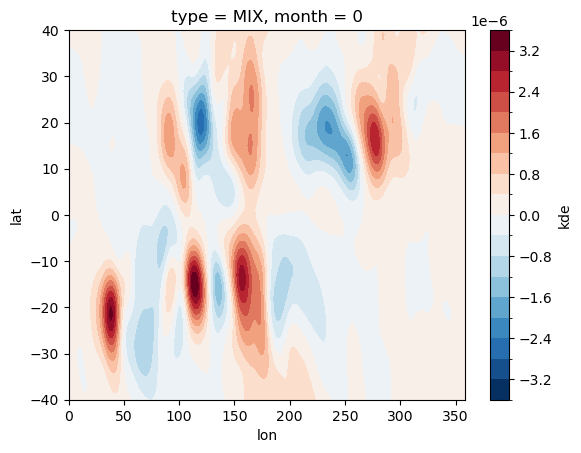

In [10]:
ds_nino.kde[0, 6].plot.contourf(levels=21)